# Design of experiments

<img src="img_notebook/doe1.png" alt="Descrizione alternativa" width="400" height="300">

### Librerie

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import qmc 
import seaborn as sns
import matplotlib.pyplot as plt

### Dominio sampling

In [2]:
# Numero di scenari base
num_scen = 256

# Numero di curvature per ogni scenario
num_curv = 4  
curv_bounds = (0.05, 0.14)

# Limiti per i parametri sampling
bounds = {
    "D_out": (32, 42),
    "Wall_Thickness": (25, 35),
    "Compression_Force": (1e6, 5e6),
    "External_Pressure":(0.5, 2),
    "Young Modulus":(190000, 230000),
    "SY1":(350, 400),
    "SY2":(450, 500),
    "EP2":(0.1, 0.2),
    "Ovalisation":(0, 0.02)
}

## Sampling

In [3]:
# Definizione dei valori di Curvature 
curvature_values = np.round(np.linspace(curv_bounds[0], curv_bounds[1], num_curv), decimals=4)

# Generazione di campioni
#sampler = qmc.LatinHypercube(d=len(bounds))
sampler = qmc.Sobol(d=len(bounds), scramble=True)

samples = sampler.random(num_scen)

# Scala i campioni nei limiti definiti
scaled_samples = qmc.scale(samples, [bounds[key][0] for key in bounds], [bounds[key][1] for key in bounds])

# Creazione della tabella base
df_samples = pd.DataFrame(scaled_samples, columns=bounds.keys())

# Espansione delle combinazioni con Curvature mantenendo tutti i dati
expanded_data = []
# Itera su ogni scenario generato
for _, row in df_samples.iterrows():
    # Per ogni scenario, combina con ogni valore di curvatura
    for curv in curvature_values:
        # Prendi tutti i valori della riga corrente e aggiungi la curvatura
        new_row = row.values.tolist() + [curv]
        expanded_data.append(new_row)

# Prende le colonne originali e aggiunge 'Curvature'
final_columns = list(df_samples.columns) + ['Curvature']

# Creazione del DataFrame completo
df_expanded = pd.DataFrame(expanded_data, columns=final_columns)

# Salvataggio della tabella in un file CSV
df_expanded.to_csv("Parameters_DoE.csv", index=False)

print(f"Tabella generata con {len(df_expanded)} righe e salvata in 'latin_hypercube_DoE.csv'")

Tabella generata con 1024 righe e salvata in 'latin_hypercube_DoE.csv'


## Graphical Plot

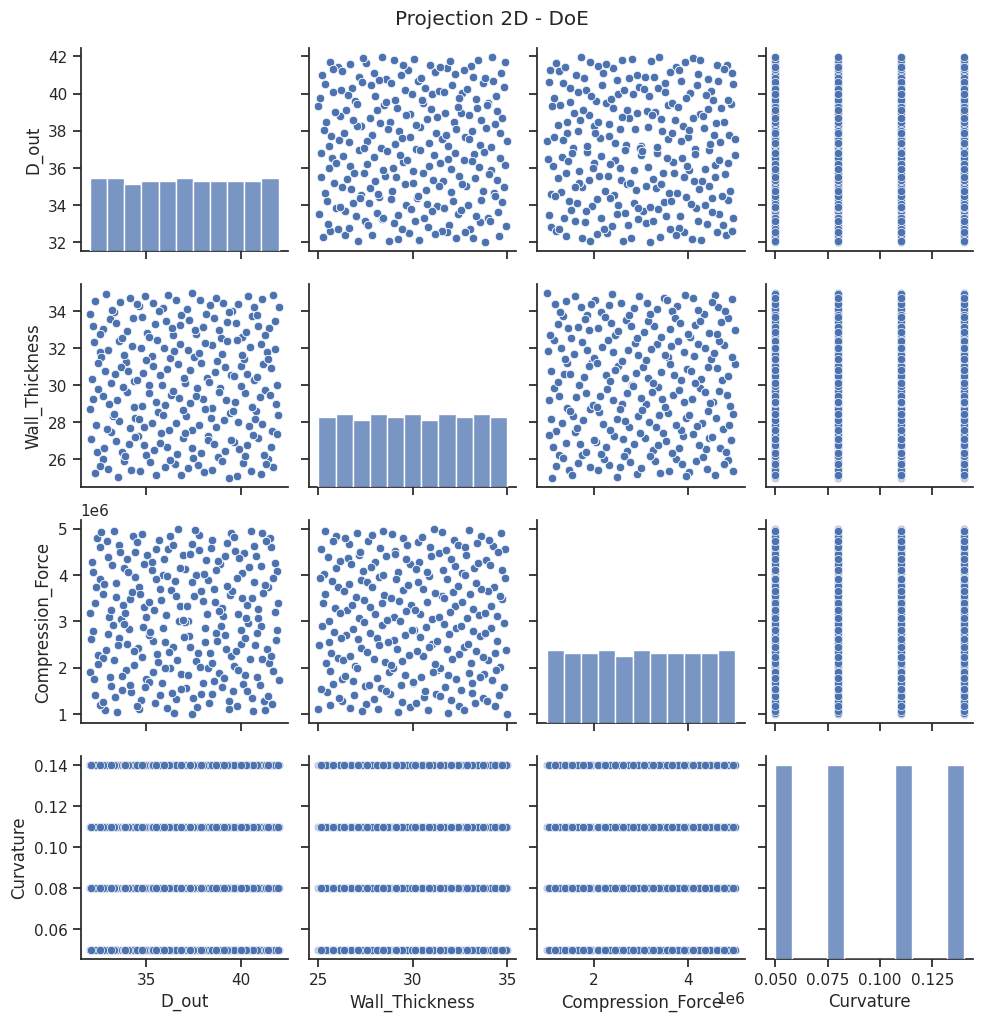

In [4]:
# Caricamento del dataset generato dallo script
try:
    df_doe = pd.read_csv("Parameters_DoE.csv")
except FileNotFoundError:
    print("Errore: Eseguire prima lo script di generazione dati per creare 'Parameters_DoE.csv'.")
    exit()

# Selezione di un sottoinsieme rappresentativo di variabili per la visualizzazione.
vars_to_plot = [
    "D_out",
    "Wall_Thickness",
    "Compression_Force",
    "Curvature"
]

# Impostazione del tema grafico
sns.set_theme(style="ticks")

# Generazione della matrice di scatter plot
# La densità dei punti sarà maggiore a causa dell'aumento del numero di campioni
pairplot_matrix = sns.pairplot(df_doe, vars=vars_to_plot)

# Aggiunta di un titolo descrittivo
pairplot_matrix.fig.suptitle("Projection 2D - DoE", y=1.02)

# Mostra il grafico
plt.show()